In [1]:
import h5py
import matplotlib.pyplot as plt
import yaml
import numpy as np
import argparse
import json
import tqdm
import io
import tarfile
import os
import math

from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib import cm
from matplotlib.colors import Normalize
from statistics import mean, mode, stdev
from pathlib import Path
from datetime import datetime

##########################################################
# Initialize parameters  
##########################################################

# early data from 5-tile cold pedestal run (before power settings were optimized, in large cryo)
#filename = "/data/v3/10x16/subset_tests_5tiles_20251028/cold/packet-cold_leakage_4tiles_cds-2025_10_29_01_31_09_PDT.h5"

# only tile 10 powered up, cold tests (before power settings were optimized, in large cryo)
#filename = "/data/v3/10x16/tile_4k04087_tests_20260206/data/cold/packet-cold_leak_10kcycles_60s_t10.hdf5"
#filename = "/data/v3/10x16/tile_4k04087_tests_20260206/data/cold/packet-cold_leak_150kcycles_120s_t10_no_hotchan.hdf5"
#filename = "/data/v3/10x16/tile_4k04087_tests_20260206/data/cold/packet-cold_leak_150kcycles_120s_t10.hdf5"
#filename = "/data/v3/10x16/tile_4k04087_tests_20260206/data/cold/packet-cold_leak_800kcycles_300s_t10_no_hotchan.hdf5"
#filename = "/data/v3/10x16/tile_4k04087_tests_20260206/data/cold/packet-cold_leak_800kcycles_300s_t10.hdf5"
#filename = "/data/v3/10x16/tile_4k04087_tests_20260206/data/cold/packet-cold_leak_1E7cycles_600s_t10_no_hotchan.hdf5"
#filename = "/data/v3/10x16/tile_4k04087_tests_20260206/data/cold/packet-cold_leak_1E7cycles_600s_t10.hdf5"

# set 1 of 10 tiles warm when too much power was drawn
#filename = "/data/v3/10x16/set1_10_tile_tests_20260214/data/warm/packet-warm_leak_10kcycles_60s_no_hotchan_185vref_10tiles.hdf5"
#filename = "/data/v3/10x16/set1_10_tile_tests_20260214/data/warm/packet-warm_leak_150kcycles_120s_no_hotchan_185vref_10tiles.hdf5"
#filename = "/data/v3/10x16/set1_10_tile_tests_20260214/data/warm/packet-warm_leak_800kcycles_300s_no_hotchan_185vref_10tiles.hdf5"
#filename = "/data/v3/10x16/set1_10_tile_tests_20260214/data/warm/packet-warm_leak_1E7cycles_600s_no_hotchan_185vref_10tiles.hdf5"

# set 2 of 9 tiles warm after grounding
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/warm/packet-warm_leak_150kcycles_120s_set2_9tiles_185vref.hdf5"
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/warm/packet-warm_leak_800kcycles_300s_set2_9tiles_185vref.hdf5"
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/warm/packet-warm_leak_5E6cycles_600s_set2_9tiles_185vref.hdf5"
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/warm/packet-warm_leak_1E7cycles_600s_set2_9tiles_185vref.hdf5"

# warm tests of set 2 of 10 tiles (tile 4 was replaced with tile 10 from set 1)
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/warm/packet-warm_leak_100kcycles_60s_set2_10tiles_185vref.hdf5"
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/warm/packet-warm_leak_300kcycles_60s_set2_10tiles_185vref.hdf5"
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/warm/packet-warm_leak_600kcycles_120s_set2_10tiles_185vref.hdf5"

# cold tests of set 2 of 10 tiles (tile 4 was replaced with tile 10 from set 1)
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/cold/packet-cold_leak_150kcycles_60s_set2_10tiles_220vref.hdf5"
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/cold/packet-cold_leak_300kcycles_120s_set2_10tiles_220vref.hdf5"
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/cold/packet-cold_leak_600kcycles_240s_set2_10tiles_220vref.hdf5"
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/cold/packet-cold_leak_800kcycles_360s_set2_10tiles_220vref.hdf5"

# cold tests of set 3 of 9 tiles (tile 1 was excluded due to networking problems)
#filename = "/data/v3/10x16/set3_10_tile_tests_20260505/data/cold/packet-cold_leak_150kcycles_60s_set3_9tiles_220vref.hdf5"
#filename = "/data/v3/10x16/set3_10_tile_tests_20260505/data/cold/packet-cold_leak_300kcycles_120s_set3_9tiles_220vref.hdf5"
#filename = "/data/v3/10x16/set3_10_tile_tests_20260505/data/cold/packet-cold_leak_600kcycles_240s_set3_9tiles_220vref.hdf5"
#filename = "/data/v3/10x16/set3_10_tile_tests_20260505/data/cold/packet-cold_leak_800kcycles_360s_set3_9tiles_220vref.hdf5"

# cold tests of set 4 of 10 tiles
#filename = "/data/v3/10x16/set4_10_tile_tests_20260512/data/cold/packet-cold_leak_150kcycles_60s_set4_10tiles_no_hotchan.hdf5"
filename = "/data/v3/10x16/set4_10_tile_tests_20260512/data/cold/packet-cold_leak_300kcycles_120s_set4_10tiles_no_hotchan.hdf5"
#filename = "/data/v3/10x16/set4_10_tile_tests_20260512/data/cold/packet-cold_leak_600kcycles_240s_set4_10tiles_no_hotchan.hdf5"
#filename = "/data/v3/10x16/set4_10_tile_tests_20260512/data/cold/packet-cold_leak_800kcycles_360s_set4_10tiles_no_hotchan.hdf5"

# the # of periodic trigger cycles specified in the filename (e.g. the "leak10) should be among this list
cycles = ['100k', '150k', '300k', '600k', '800k']

# use the data filename to determine if this is a cold or warm run, and set the pedestal
# file date accordingly
temp = "cold"

if temp not in filename:
    temp = "warm"
    if temp not in filename:
        print(f"The file name doesn't indicate if this data was taken warm or cold")
        temp = "unspecified temperature"
    
# tiles potentially tested in this filename
tiles = [1,2,3,4,5,6,7,8,9,10]
#tiles = [2,3,4]
#tiles = [10]
ntiles = len(tiles)

# set the # of individual channels to graph
n_to_graph = 3
n_graphed = 0

# serial numbers for set 1 of tiles 1-10
chip_serial_number_list = ['', '4k02056', '4k03591', '4k01892', '4k02219', '4k02371', '4k04834', '4k00101', '4K00277', '4K03329', '4K04087' ]

# serial numbers for sets 2 and 3 
if "set2" in filename:
    chip_serial_number_list = ['', '4k04582', '4k04905', '4k03080', '4k04087', '4k04249', '4k00104', '4k01300', '4K04411', '4K01733', '4K00770' ]
elif "set3" in filename:
    chip_serial_number_list = ['', '4k00952', '4k03591', '4k03936', '4k00607', '4k00450', '4k04834', '4k00101', '4K00277', '4K03329', '4K03496' ]
elif "set4" in filename:
    chip_serial_number_list = ['', '4k01892', '4k02056', '4k02219', '4k02371', '4k00450', '4k04834', '4k00101', '4K00277', '4K03329', '4K03496' ]    

# if certain channels are known to be problematic, and you don't want them skewing the pedestal distributions,
# specify them here. These channels will not be analysed
#omitted_channels = [0,56,57]
omitted_channels = []

# the number of standard deviations to qualify a dataword as "high" to identify potential leakage candidates
nstdev = 3

# Setting verbose = True will print out various pieces of chip-level or packet-level information 
verbose = False
verbose_tile = 2
verbose_chip = 40
verbose_chan = 30

# initialize
ig = 1 
first_tile = True
n_chan56 = 0
n_chan_in_tile = 160 * 64
chan56_stdev = []
n_high_file = 0
leakage_count_file, noisy_count_file = 0,0
leakage_counts = []
mean_of_means = [] 
means = [[] for ch in range(64)]
leakage_means  = [[[0 for chan in range(64)] for chip in range(171)] for tile in range(11)]
leakage_stdevs = [[[0 for chan in range(64)] for chip in range(171)] for tile in range(11)]
mean_word      = [[[0 for chan in range(64)] for chip in range(171)] for tile in range(11)]
chan_list = []
stdev_high_list = []
file_cycles = 0

# pedestals will be read from a datafile
pedestals  = [[[0 for chn in range(64)] for chp in range(171)] for tile in range(11)] 
ped_stdevs = [[[0 for chn in range(64)] for chp in range(171)] for tile in range(11)] 

# background: packet dataset attributes: 
# ('io_group', 'io_channel', 'chip_id', 'packet_type', 'downstream_marker', 'parity', 'valid_parity', 'channel_id', 
# 'timestamp', 'dataword', 'trigger_type', 'local_fifo', 'shared_fifo', 'register_address', 'register_data', 'direction', 
# 'local_fifo_events', 'shared_fifo_events', 'counter', 'fifo_diagnostics_enabled', 'first_packet', 'receipt_timestamp')


In [2]:
def get_io_channels(tile):

    io_ch_per_tile = [
        [],
        [1,2,3,4],
        [5,6,7,8],
        [9,10,11,12],
        [13,14,15,16],
        [17,18,19,20],
        [21,22,23,24],
        [25,26,27,28],
        [29,30,31,32],
        [33,34,35,36],
        [37,38,39,40]
        ]
    
    return io_ch_per_tile[tile]


In [3]:
def get_data(filename, tile, ig):
    
    global chip_serial_number, first_tile, n_chan56, n_high_file, chan56_stdev, nstdev, mean_of_means, stdev_high_list
    global pedestals, noisy_count_file, leakage_count_file, leakage_means, leakage_stdevs, cycles, file_cycles, n_low_leak
    global verbose_tile, verbose_chip, verbose_chan, leakage_countsj, omitted_channels, mean_word
    global tile_result_keys, results, n_to_graph, n_graphed
    
    chan_nstdev, leakage_count, noisy_count = 0, 0, 0
    leakage_list = []
    stdev_chan56_list = []
    leak_chan56_list, leak_verbose_list = [], []
    leakage = [[[[] for chn in range(64)] for chp in range(171)] for tile in range(11)]
    nchan_1_pkts, nchan_no_pkts, n_low_leak = 0,0,0

    # read packet data from initialized file name
    f = h5py.File(filename, 'r')
    packets = f['packets'][:]
    
    # create arrays of data packets
    data_mask     = f['packets'][:]['packet_type']  == 1
    data_pkts     = packets[data_mask]

    # identify io_channels with data packets in this data file
    unique_io_channels = list(dict.fromkeys(data_pkts['io_channel'][:]))
    unique_io_channels = sorted(unique_io_channels)

    # print out run statistics for the file
    if first_tile:

        unixtime = f['packets'][:]['timestamp'][f['packets'][:]['packet_type'] == 4]
        livetime = np.max(unixtime)-np.min(unixtime)        
        npkts         = len(data_pkts) 
        
        print(f"\t{npkts:,} data packets for tile {tile} arriving at an average rate of {npkts/livetime:.0f} pkts/s over {livetime}s of data taking") 
        print(f"\tIO_channels in file: {[int(x) for x in unique_io_channels]}")

        found_cycles = False 
        for c in cycles:
            if c in filename:
                file_cycles = c
                found_cycles = True
                continue
    
        if found_cycles:
            print(f'\t{file_cycles} periodic trigger cycles were configured for this datafile')            
        else:
            print('#### PROBLEM: the periodic trigger cycles for this file was either not listed in the cycles array or in the filename')
        
        first_tile = False

    # get a list of the io_channels that could be enabled for a given tile, and then determine which
    # ones had data
    io_channel_ids = get_io_channels(tile)
    enabled_io_channels = list(set(io_channel_ids) & set(unique_io_channels))
    
    # mask for the chosen tile
    tile_mask = (data_pkts['io_channel']== io_channel_ids[0]) | (data_pkts['io_channel']== io_channel_ids[1]) | (data_pkts['io_channel']== io_channel_ids[2]) | (data_pkts['io_channel']== io_channel_ids[3])
    data_pkts = data_pkts[tile_mask]

    # determine various tile attributes
    unique_chips = list(dict.fromkeys(data_pkts['chip_id'][:]))    
    npkts_tile = len(data_pkts) 
    data_chips = data_pkts['chip_id'][:]
    unique_chips = list(dict.fromkeys(data_chips))

    # serial #s uniquely identifying the chip located in the top left corner of each tile, when looking at it with 
    # the power and data connectors at the top. The following key is needed when storing results in the dictionary
    tile_result_keys = ['', '4k04582', '4k04905', '4k03080', '4k04087', '4k04249', '4k00104', '4k01300', '4K04411', '4K01733', '4K00770', \
                     '4k00952', '4k03591', '4k03936', '4k00607', \
                     '4k01892', '4k02056', '4k02219', '4k02371', '4k00450', '4k04834', '4k00101', '4K00277', '4K03329', '4K03496']
    
    if chip_serial_number in tile_result_keys:
        tile_index = tile_result_keys.index(chip_serial_number)
    else:
        print(f"\nProblem: tile {chip_serial_number} was not found in the results dictionary tile list. Its results will not be stored")
  
    
    print(f"\n\n############################ Checking Tile {tile} ###################################")
    print(f'Run Statistics for Tile {tile}:')    
    print(f'\t{npkts_tile:,} packets from io_channels {enabled_io_channels} (~{npkts_tile / (160*64):.0f} pkts per channel)')
    print(f'\t{len(unique_chips)} chips were recorded') 
    
    if npkts_tile ==0: 
        print(f'There are no data packets for tile {tile}')        
        return

    # mean pedestal values for each channel are read from a previously created file
    get_pedestals(tile, chip_serial_number)
    
    # determine the mean and stdev of non-zero adc datawords for this tile
    tile_adc = data_pkts['dataword']
    non_zero_adc = tile_adc[tile_adc != 0]
    non_zero_adc_list = non_zero_adc.tolist()       
    mean_tile_adc = np.mean(non_zero_adc_list)     
    
    if len(non_zero_adc) > 1:
        stdev_tile_adc = np.std(non_zero_adc_list) 
    else: 
        stdev_tile_adc = 0  
        print(f'###### PROBLEM: Can not calculate adc stdev for tile {tile} - there were only {len(non_zero_adc)} non-zero adc values')

    print(f'\tADC Dataword mean {mean_tile_adc:.0f} and Stdev {stdev_tile_adc:.0f}') 

    boundary = mean_tile_adc + nstdev * stdev_tile_adc
    
    # plot the datawords before subtracting the pedestal
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.hist(non_zero_adc_list, bins = 100, color = 'lime')
    ax.set_title(f'Datawords from Leakage File (Mean {mean_tile_adc:.0f})\n{temp} Leakage test @ {file_cycles} trigger cycles, v3a Tile #{tile} ({chip_serial_number})')
    ax.set_xlabel(f'ADC Dataword (before subtracting pedestal)')
    ax.set_yscale('log')
    ax.axvline(x = boundary, color='r', linestyle='--')    
    ax.set_ylabel(f'# Datawords > {nstdev}SD')
    
    # initialize counts for channels with high means for dataword-pedestal 
    nhigh_tile = 0
    nhigh_chip_list, nhigh_chan_list, chip_list, stdev_list = [], [], [], []
    
    # create arrays to determine mean and stdev of (dataword-pedestal) for each tile
    for chip in unique_chips:

        if chip not in range(11,171):
            print(f'\tPackets from Misnumbered Chip {chip} will not be considered in this analysis')
            continue
        
        # mask for chip and get chip values
        chip_mask = data_pkts['chip_id'] == chip
        chip_pkts = data_pkts[chip_mask]
        chip_adc  = chip_pkts['dataword'][:]
        chip_chans = chip_pkts['channel_id'][:]
        unique_channels = list(dict.fromkeys(chip_chans))
        npkts_chip = len(chip_pkts)
        
        chip_list.append(chip)
        
        for chan in unique_channels:

            if chan in omitted_channels:
                continue

            # mask for channel
            chan_mask = chip_pkts['channel_id'] == chan
            chan_pkts = chip_pkts[chan_mask]
            chan_adc  = chan_pkts['dataword']
            
            # remove zero datawords
            non_zero_chan_adc = chan_adc[chan_adc != 0]

            if len(non_zero_chan_adc) > 1:
            
                # subtract pedestals from the dataword to test for leakage current. Create a list used later for mean and stdev for the tile
                leakage[tile][chip][chan] = [x - pedestals[tile][chip][chan] for x in non_zero_chan_adc]
                leakage_list.extend(leakage[tile][chip][chan])
                mean_word[tile][chip][chan] = np.mean(non_zero_chan_adc)
                    
                leakage_means[tile][chip][chan] = np.mean(non_zero_chan_adc) - pedestals[tile][chip][chan]

                stdev_chan = np.std(leakage[tile][chip][chan])
                leakage_stdevs[tile][chip][chan] = stdev_chan
                stdev_list.append(stdev_chan)

                if leakage_means[tile][chip][chan] < -50:
                    n_low_leak +=1
                    print(f"\nPROBLEM: Tile-Chip-Chan {tile}-{chip}-{chan} had an extraordinarily low leakage mean of {leakage_means[tile][chip][chan]}") 
                    print(f"\tIt had {len(non_zero_chan_adc)} leakage packets with mean {np.mean(non_zero_chan_adc)} & pedestal {pedestals[tile][chip][chan]}")
                    
                # load the results dictionary
                results['leakage_mean'][tile_index][chip][chan]   = leakage_means[tile][chip][chan]
                results['leakage_stdev'][tile_index][chip][chan]  = stdev_chan            
            
            else:
                print(f'channel {tile}-{chip}-{chan}: can not calculate stdev and/or mean. There are only {len(chan_pkts)} packets')

            if tile == verbose_tile and chip == verbose_chip and chan == verbose_chan:
                leak_verbose_list.append(leakage[tile][chip][chan])

    # determine the mean and stdev of (dataword-pedestal) for the tile. "Boundary" defines the test for "high" dataword-pedestal values
    leakage_stdev_tile = np.std(leakage_list)
    leakage_mean_tile  = np.mean(leakage_list)
    boundary = leakage_mean_tile + nstdev * leakage_stdev_tile

    print(f'\tTile {tile} mean(dataword-pedestal) = {leakage_mean_tile:.0f}, stdev(datword-pedestal) = {leakage_stdev_tile:.1f}')

    # identify channels with (dataword-pedestal) > boundary (set above)
    for chip in unique_chips:

        # skip misnumbered chips
        if chip not in range(11,171):
            continue

        # initialize
        chan_list, mean_list = [], []
        n_high_chan = 0
        high_chan_ids = []
        
        for chan in range(64):

            if chan in omitted_channels:
                continue
            
            npkts_chan = len(leakage[tile][chip][chan])
            
            # count the % of packets with adc datawords > boundary
            if npkts_chan > 1:

                # calculate the mean and the # of stdev the channel's mean is from the tile's mean
                mean_chan = np.mean(leakage[tile][chip][chan])    
                nstdev_chan = (mean_chan - leakage_mean_tile) / leakage_stdev_tile
                                
                # qualification for the somewhat arbitrarily assigned definition of "high" leakage current
                if nstdev_chan > nstdev and chan not in omitted_channels:
                    n_high_chan +=1             # count high channels for each chip
                    n_high_file +=1             # count high channels in the entire file
    
                    stdev_high_list.append(np.std(leakage[tile][chip][chan]))
    
                    # determine if this channel's stdev indicates a noisy channel or a leakage candidate
                    if stdev_high_list[-1] < 2 * leakage_stdev_tile:
                        if chan in omitted_channels:
                            continue
                        leakage_count +=1
                        if verbose:
                            print(f"\nLeakage Candidate Tile-Chip-Chan: {tile}-{chip}-{chan}")
                            print(f'\tChip-Channel {chip}-{chan}: mean {mean_chan:.0f} was {nstdev_chan:.0f} stdev from tile mean. Pedestal {pedestals[tile][chip][chan]:.0f}. Stdev {stdev_high_list[-1]:.0f}. Npkts {npkts_chan}')
                    else:
                        noisy_count +=1
                        
                    high_chan_ids.append(chan)
                
                mean_list.append(mean_chan)
                chan_list.append(chan)

                # keep track of the mean for every specific channel id to see if there is a pattern of high values for a specific channel id
                # this might indicate there is leakage due to where a particular channel is located on the chip
                means[chan].append(mean_chan)

            else:
                #print(f"\nTile-chip {tile}-{chip}-{chan} was not tested. It only had {npkts_chan} packets")
                if npkts_chan ==0:
                    nchan_no_pkts +=1
                else:
                    nchan_1_pkts +=1
        
        # a list for graphing the # of high channels per chip for the tile
        nhigh_chip_list.append(n_high_chan)
        
        # for channels w high means, graph dataword-pedestal for each channel on the chip
        if n_high_chan > 0 and n_graphed < n_to_graph:

            n_graphed +=1
            
            fig, axis = plt.subplots(1,2, figsize=(10, 3))
            plt.suptitle(f'Tile-Chip {tile}-{chip}: Channels with Mean(dataword-pedestal) > {nstdev}SD: {[int(x) for x in high_chan_ids]})\n{temp} Leakage test @ {file_cycles} trigger cycles, v3a Tile #{tile} ({chip_serial_number})')

            # overlay the time series of dataword-pedestal for each channel
            for chan in range(len(unique_channels)):
                if chan in omitted_channels:
                    continue
                axis[0].plot(leakage[tile][chip][chan])
            
            axis[0].set_xlabel(f'Packet')
            axis[0].set_ylabel(f'Mean Dataword-Pedestal') 
            plt.text(20, boundary + 5, '3 Stdev for Tile', color='red', style='italic')
            plt.yscale('log')
            axis[0].axhline(y = boundary, color='r', linestyle='--')
                
            # graph mean versus channel
            axis[1].bar(chan_list, mean_list)
            axis[1].set_xlabel(f'Channel')
            #axis[1].set_ylabel(f'Mean Dataword-Pedestal')
            axis[1].axhline(y = boundary, color='r', linestyle='--')            
            plt.tight_layout()
            plt.show

    print(f'\n{nchan_1_pkts} channels only had 1 pkt')
    print(f'\n{nchan_no_pkts} channels had 0 pkts') 
    print(f'\n{n_low_leak} channels had leakage mean < -100')

    print(f'\nAmong the channels with High Mean(Dataword-Pedestal) (i.e. > {nstdev} Stdev from Tile Mean):')
    print(f'\t{noisy_count} channels had high stdev (i.e. noisy) \n\t{leakage_count} channels had low stdev (i.e. leakage candidates before linearity test)')
    leakage_count_file += leakage_count
    noisy_count_file += noisy_count

    leakage_counts.append(leakage_count)
    
    # histogram stdev by channel
    fig, ax = plt.subplots(figsize=(6, 3))
    plt.hist(stdev_list, bins = 500)
    ax.set_title(f'Stdev(Dataword - Pedestal) by Channel\n{temp} Leakage test @ {file_cycles} trigger cycles, v3a Tile #{tile} ({chip_serial_number})')
    ax.set_xlabel(f'Standard Deviation (Dataword - Pedestal)')
    #ax.axvline(x = 2*leakage_stdev_tile, color='r', linestyle='--')     
    ax.set_ylabel(f'# Channels') 
    ax.set_yscale('log')
    ax.set_xlim(0, max(stdev_list))
    plt.show  
    
    # count the total number of high channels for the tile (for the graph title)
    nhigh_channels = sum(nhigh_chip_list)
    
    fig, ax = plt.subplots(1,1, figsize=(6, 3))
    # plot the number of high channels by chip for the given tile
    ax.bar(chip_list, nhigh_chip_list)
    ax.set_title(f'{nhigh_channels} Channels Mean Dataword - Pedestal > {nstdev}SD\n{temp} Leakage test @ {file_cycles} trigger cycles, v3a Tile #{tile} ({chip_serial_number})')
    ax.set_xlabel(f'Chip')
    ax.set_ylabel(f'# Channels') 
    plt.show  

    fig, ax = plt.subplots(1,1, figsize=(6, 3))
    ax.hist(leakage_list, bins = 100)
    ax.set_title(f'Dataword-Pedestal (Mean {leakage_mean_tile:.0f})\n{temp} Leakage test @ {file_cycles} trigger cycles, v3a Tile #{tile} ({chip_serial_number})')
    ax.set_xlabel(f'Dataword-Pedestal')
    ax.set_yscale('log')
    ax.axvline(x = boundary, color='r', linestyle='--')    
    ax.set_ylabel(f'Packet Count')
    
    # histogram all dataword-pedestal for the verbose channel
    if tile == verbose_tile:
        leakage_stdev_verbose = np.std(leak_verbose_list)
        leakage_mean_verbose  = np.mean(leak_verbose_list)
        pedestal_verbose = pedestals[verbose_tile][verbose_chip][verbose_chan]
        print(f"\nVerbose Channel {verbose_tile}-{verbose_chip}-{verbose_chan}: mean {leakage_mean_verbose:.2f}, stdev {leakage_stdev_verbose:.2f}, pedestal {pedestal_verbose:.0f}")
        
        fig, ax = plt.subplots( figsize=(6, 4) )
        plt.title(f'Verbose Channel {verbose_chip}-{verbose_chan}: Dataword-Pedestal\n{temp} Leakage test (Pedestal {pedestal_verbose})\n{file_cycles} trigger cycles, v3a Tile #{tile} ({chip_serial_number})')    
        ax.hist(leak_verbose_list, bins = 100)
        ax.set_xlabel(f'Dataword-Pedestal')
        ax.set_yscale('log')
        ax.axvline(x = leakage_mean_tile, color='r', linestyle='--')    
        ax.set_ylabel(f'Packet Count')
        plt.show      
    
    return

In [4]:
def get_pedestals(tile, serial_number):

    global pedestals, filename, temp, pedestal_file, ped_stdevs
    
    # make sure the pedestal file is from the same warm or cold condition

    # the pedestal file
    pedestal_file = f'../data/pedestals_{temp}_tile{tile}_{serial_number}.hdf5'
        
    # create an array of packets from the data file
    f=h5py.File(pedestal_file, 'r')

    pedestals[tile] = f['pedestals'][:]
    ped_stdevs[tile] = f['stdevs'][:]    
    
    f.close()  

    print(f"\tPedestals read from {pedestal_file}")

    mean_pedestal = np.mean(pedestals[tile])
        
    # graph the pedestals for this tile
    if verbose:
        fig, ax = plt.subplots(1,1, figsize=(6, 3))        
        plt.title(f'Tile {tile}: Pedestals per Channel (Mean {mean_pedestal:.0f})\n {temp} test of v3a Tile #{tile} ({serial_numbers[tile]})')
        ax.hist(pedestals[tile], bins = 200)
        ax.set_xlabel(f'Pedestal')
        ax.set_ylabel(f'Channel Count')
    
        plt.show
    
    
    return

In [5]:
def write_leakage_to_file(tile):

    global temp, leakage_means, leakage_stdevs, file_cycles, chip_serial_number, pedestals, ped_stdevs
    
    # create a file of leakage (mean and stdev) by channel
    filename = f'../data/leakage_{temp}_tile{chip_serial_number}_{file_cycles}cycles.hdf5'

    dtype = h5py.vlen_dtype(np.dtype('float'))
        
    with h5py.File(filename, 'w') as f:

        dset_leakage_means   = f.create_dataset('leakage_means' ,  shape=(171,), dtype = dtype)   
        dset_leakage_stdevs  = f.create_dataset('leakage_stdevs',  shape=(171,), dtype = dtype)   
        dset_ped_stdevs      = f.create_dataset('ped_stdevs'    ,  shape=(171,), dtype = dtype) 
        
        for chip in range(11,171):
    
            dset_leakage_means[chip]   = leakage_means[tile][chip]
            dset_leakage_stdevs[chip]  = leakage_stdevs[tile][chip]           
            dset_ped_stdevs[chip]      = ped_stdevs[tile][chip]   
            
        f.close()

    print(f'\nTile {tile}: Leakage Means, leakage Stdev & Pedestal Stdev written to file {filename}')
        
    return


In [6]:
# import the dictionary which logs test results by channel for all v3a tests
def import_results_dictionary():

    global results, results_filename, temp

    # establish filename that holds the results dictionary
    first_tile = 1
    last_tile = 24
    chip_version  = "v3a"
    date = "2026-06-29_08:29"
    results_filename = f'/data/v3/10x16/results_{chip_version}_tiles_{first_tile}-{last_tile}_{temp}_created_{date}.hdf5'

    with h5py.File(results_filename, "r") as f:
        results = {}
        for key, item in f.items():
            data = item[()]
            results[key] = data    

    print(f'\tResults dictionary read from file {results_filename}')
          
    return

In [7]:
def store_results():

    global results, results_filename
    
    with h5py.File(results_filename, 'w') as f:
        
        for key, chan_list in results.items():
            f.create_dataset(key, data=np.array(chan_list))
    
        f.close()  
        
    print(f"\n\nUpdated results dictionary in {results_filename}") 

    return

Run Statistics for Data File /data/v3/10x16/set4_10_tile_tests_20260512/data/cold/packet-cold_leak_300kcycles_120s_set4_10tiles_no_hotchan.hdf5:
	Results dictionary read from file /data/v3/10x16/results_v3a_tiles_1-24_cold_created_2026-06-29_08:29.hdf5
	17,409,966 data packets for tile 1 arriving at an average rate of 159724 pkts/s over 109s of data taking
	IO_channels in file: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 17, 18, 19, 21, 22, 23, 25, 26, 27, 29, 30, 31, 33, 34, 35, 37, 38, 39]
	300k periodic trigger cycles were configured for this datafile


############################ Checking Tile 1 ###################################
Run Statistics for Tile 1:
	1,731,251 packets from io_channels [1, 2, 3, 4] (~169 pkts per channel)
	159 chips were recorded
	Pedestals read from ../data/pedestals_cold_tile1_4k01892.hdf5
	ADC Dataword mean 285 and Stdev 5
	Tile 1 mean(dataword-pedestal) = -0, stdev(datword-pedestal) = 2.9

0 channels only had 1 pkt

0 channels had 0 pkts

0 channels

/tmp/ipykernel_199190/1214349896.py:107: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(5, 3))


	Tile 5 mean(dataword-pedestal) = -0, stdev(datword-pedestal) = 3.4

0 channels only had 1 pkt

0 channels had 0 pkts

0 channels had leakage mean < -100

Among the channels with High Mean(Dataword-Pedestal) (i.e. > 3 Stdev from Tile Mean):
	8 channels had high stdev (i.e. noisy) 
	55 channels had low stdev (i.e. leakage candidates before linearity test)

Tile 5: Leakage Means, leakage Stdev & Pedestal Stdev written to file ../data/leakage_cold_tile4k00450_300kcycles.hdf5


############################ Checking Tile 6 ###################################
Run Statistics for Tile 6:
	1,742,157 packets from io_channels [21, 22, 23] (~170 pkts per channel)
	160 chips were recorded
	Pedestals read from ../data/pedestals_cold_tile6_4k04834.hdf5
	ADC Dataword mean 285 and Stdev 5
	Tile 6 mean(dataword-pedestal) = -0, stdev(datword-pedestal) = 3.0

0 channels only had 1 pkt

0 channels had 0 pkts

0 channels had leakage mean < -100

Among the channels with High Mean(Dataword-Pedestal) (i.e. > 3

<function matplotlib.pyplot.show(close=None, block=None)>

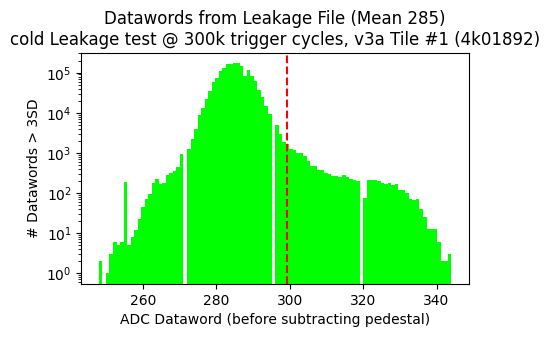

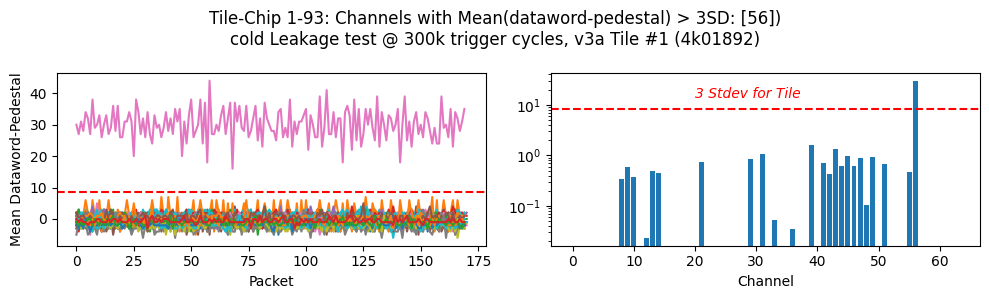

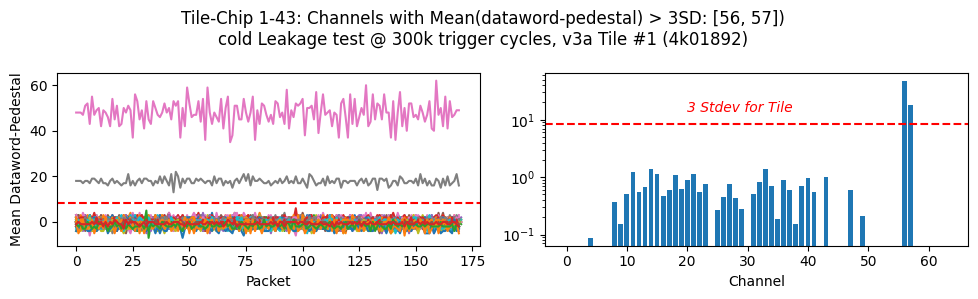

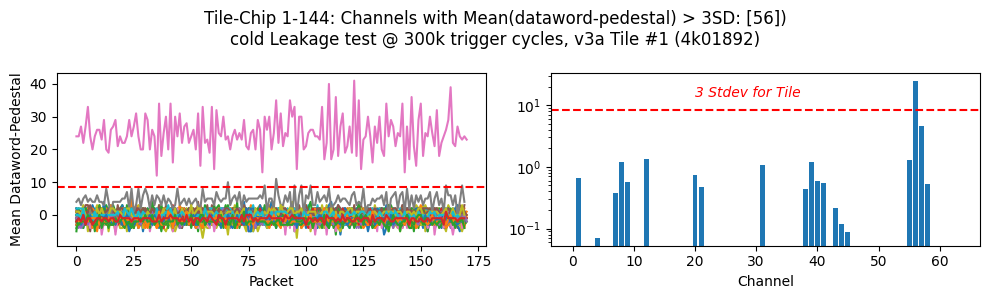

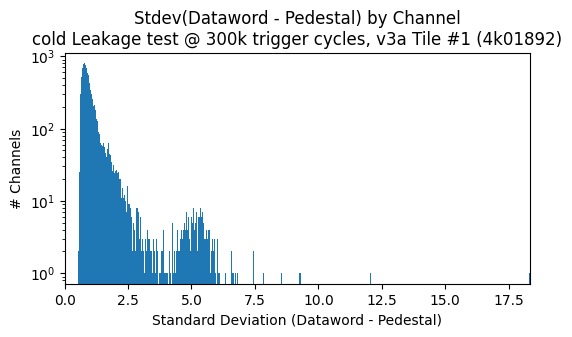

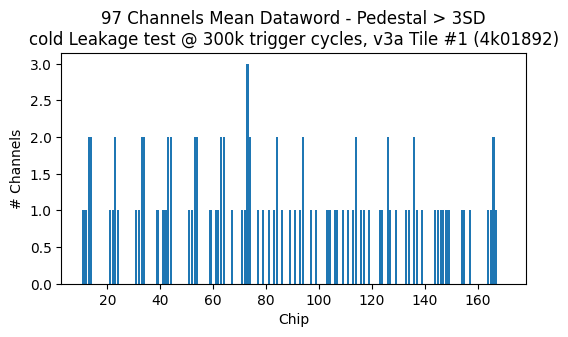

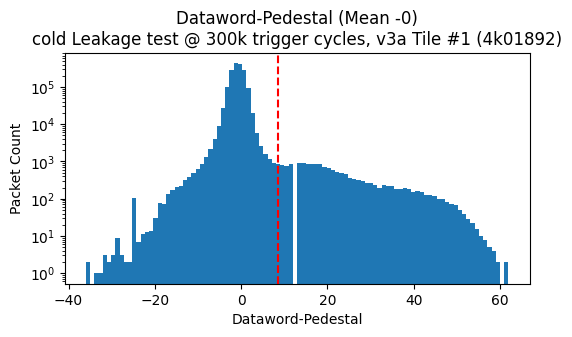

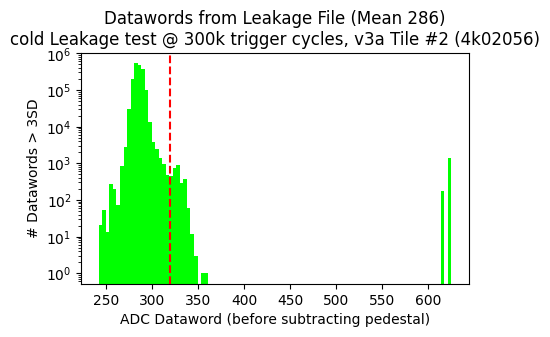

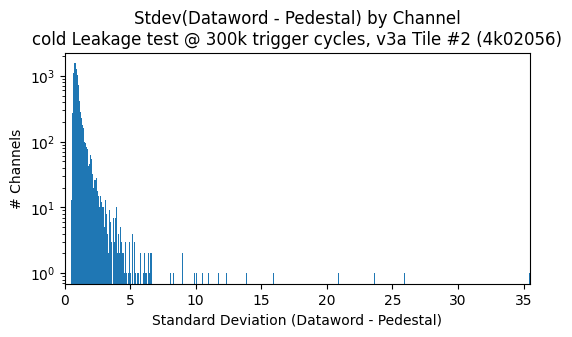

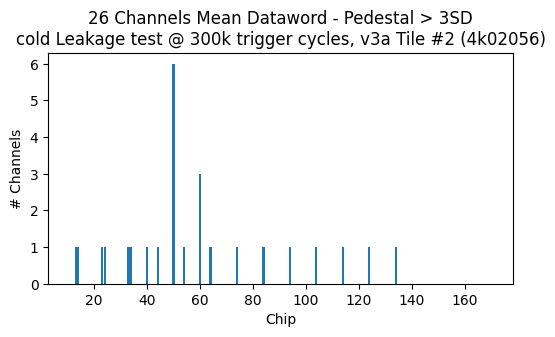

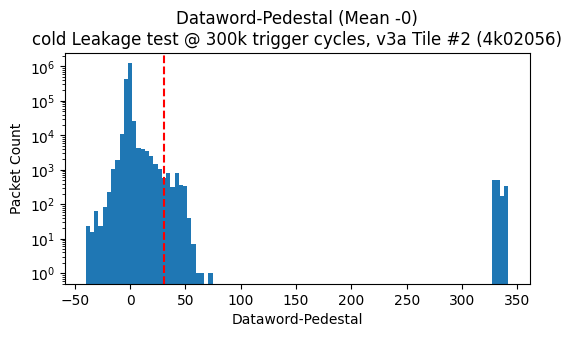

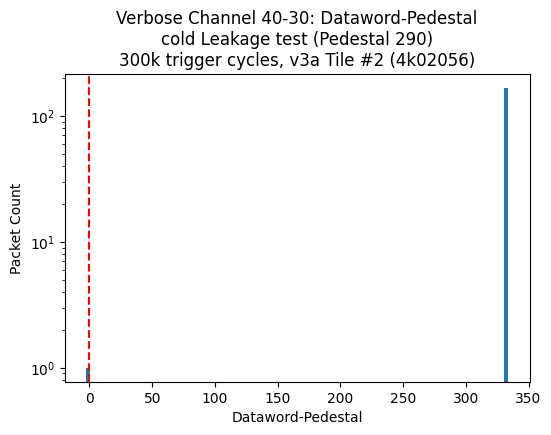

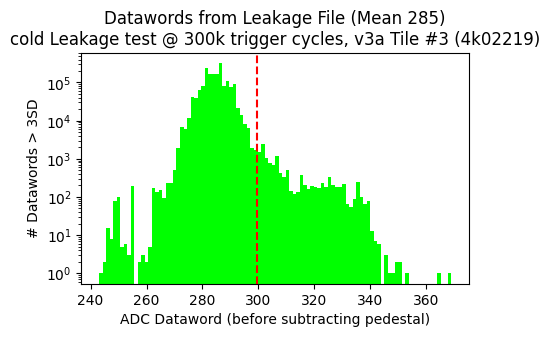

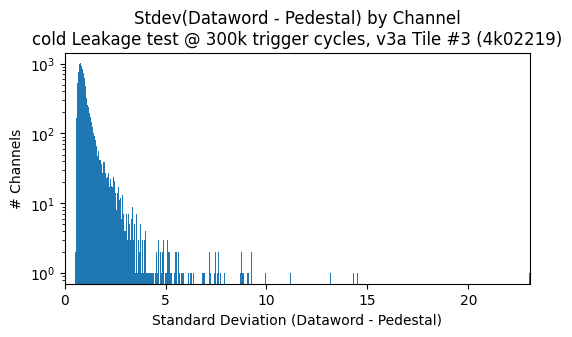

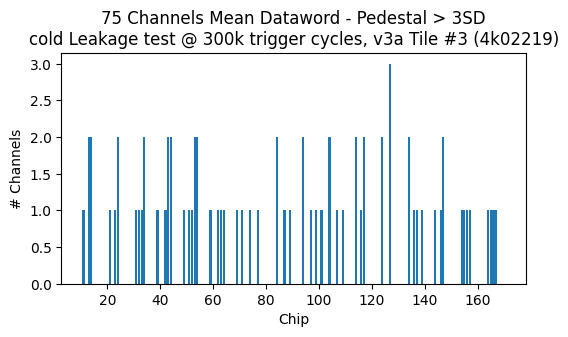

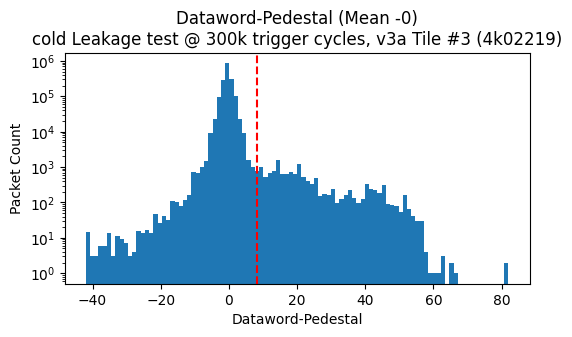

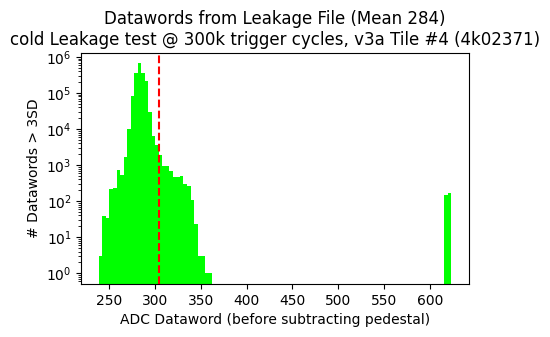

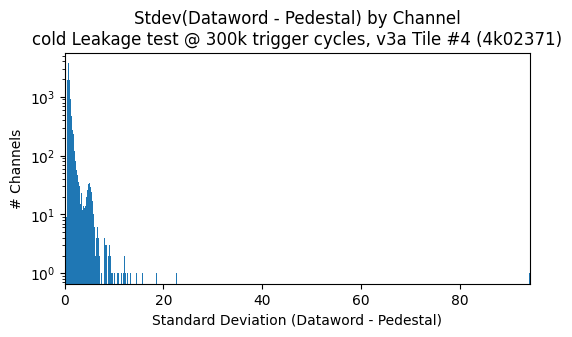

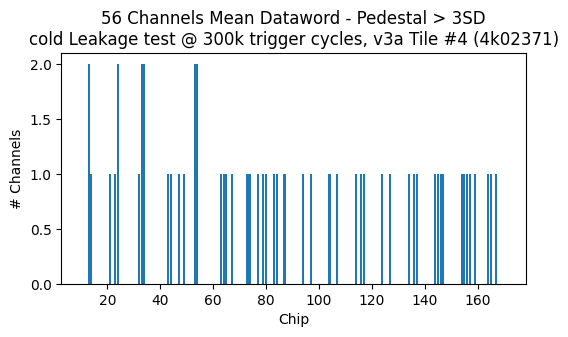

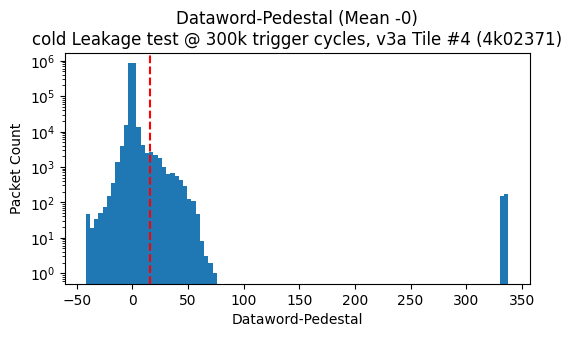

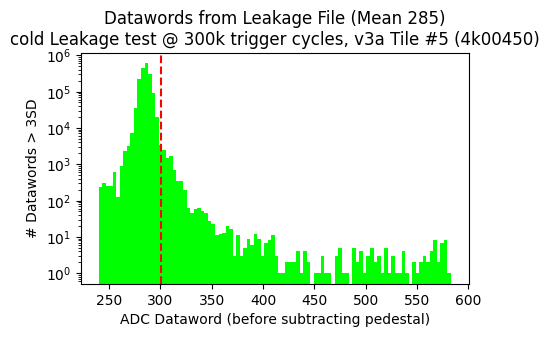

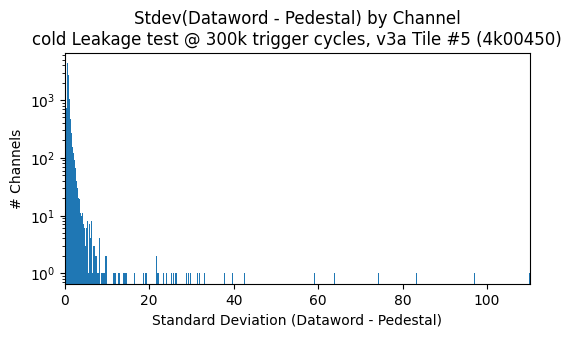

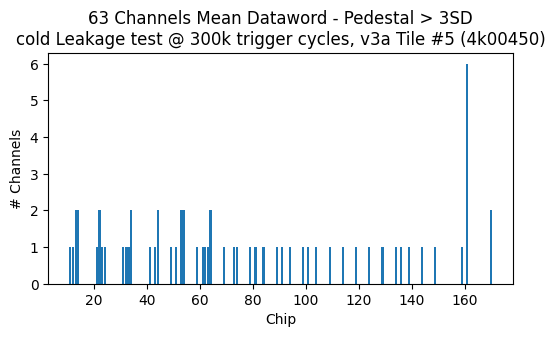

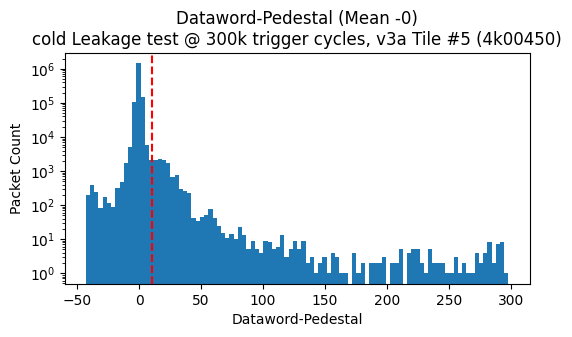

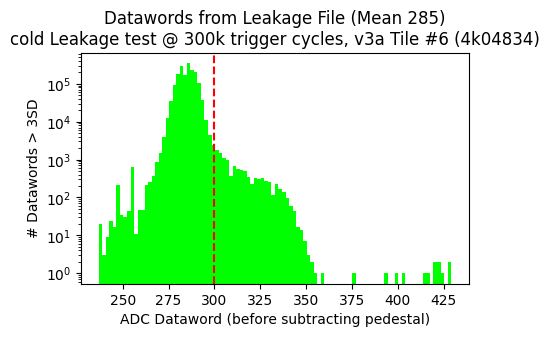

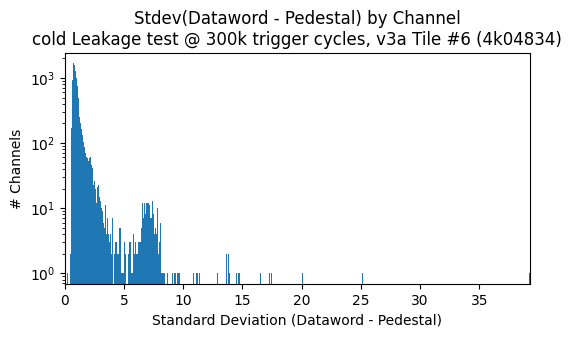

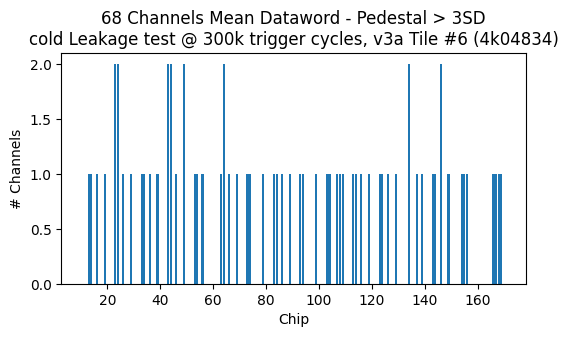

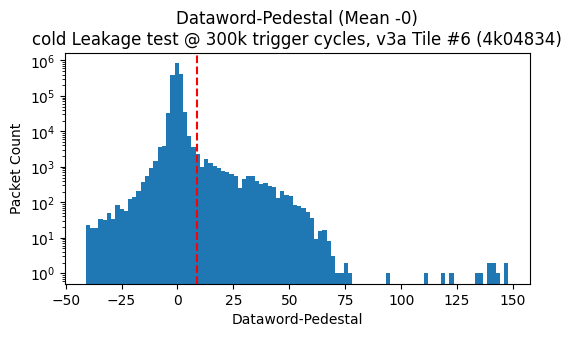

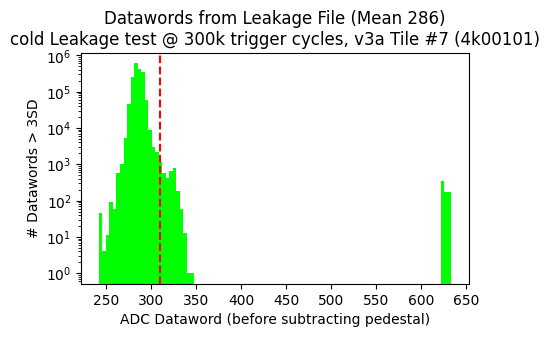

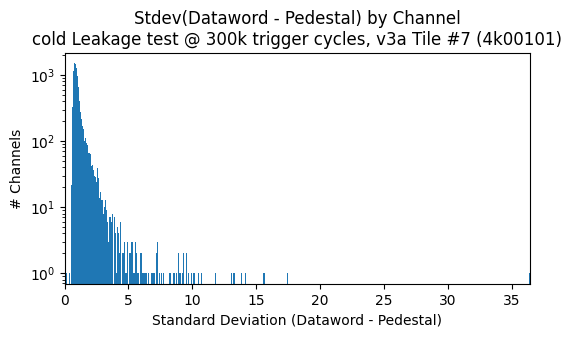

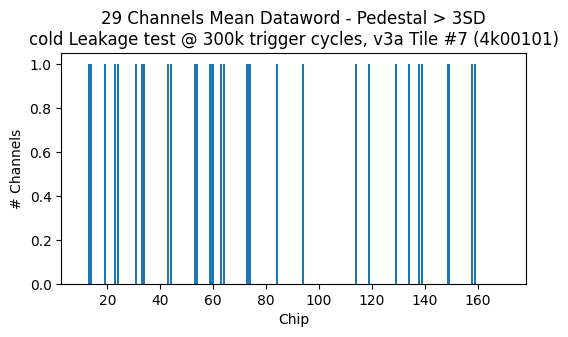

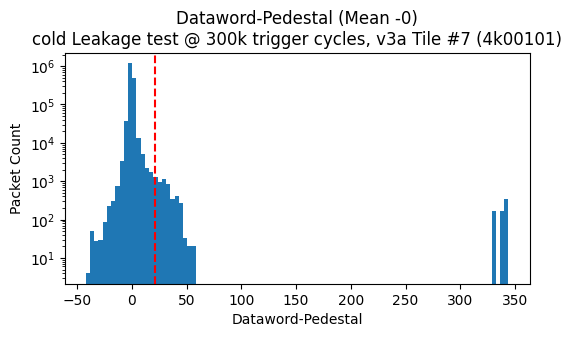

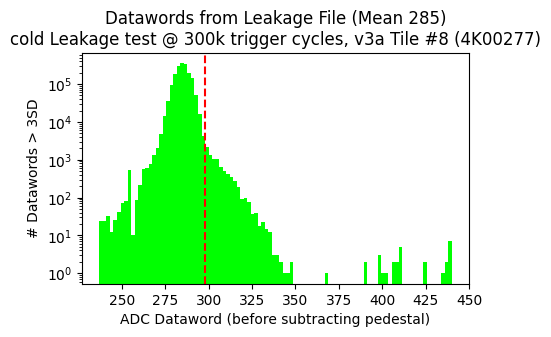

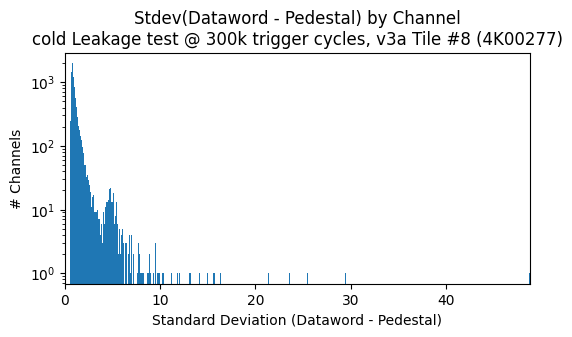

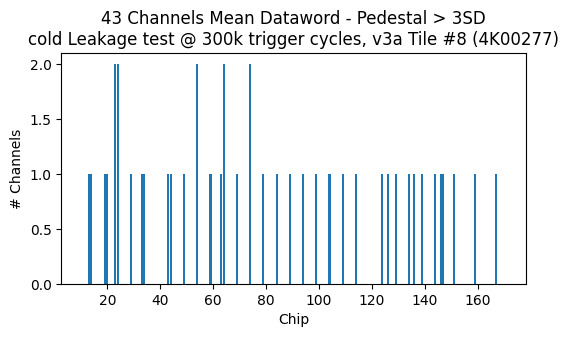

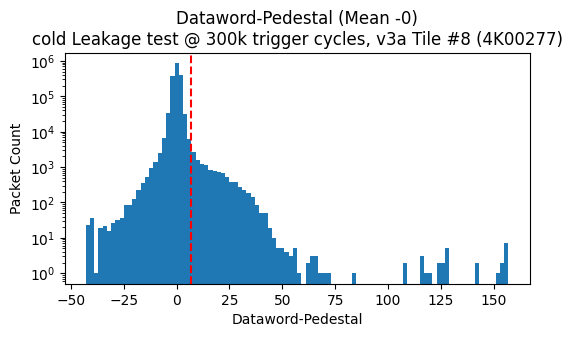

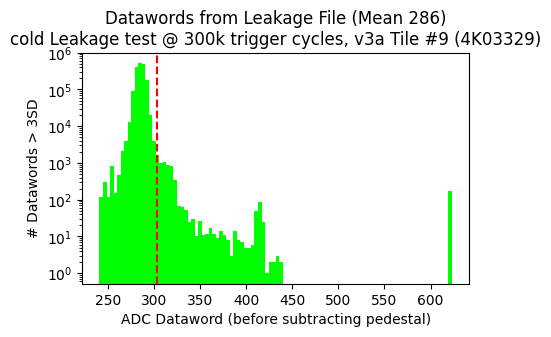

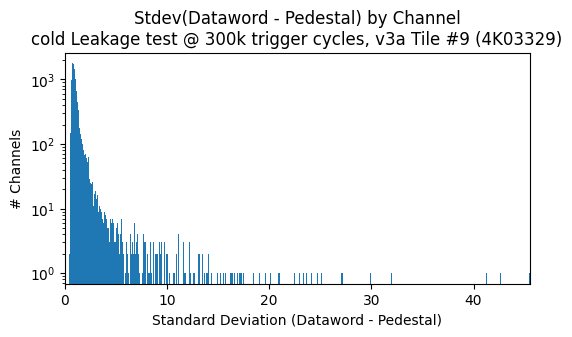

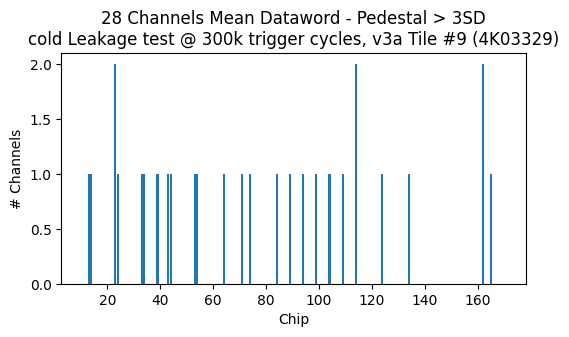

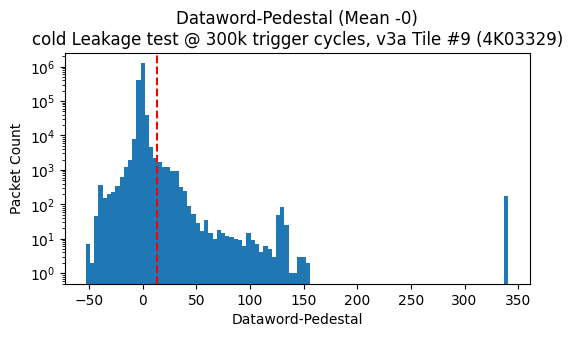

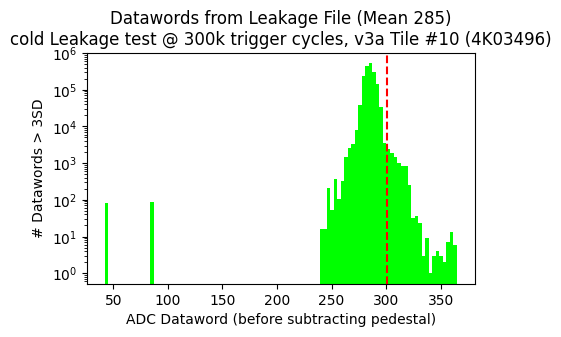

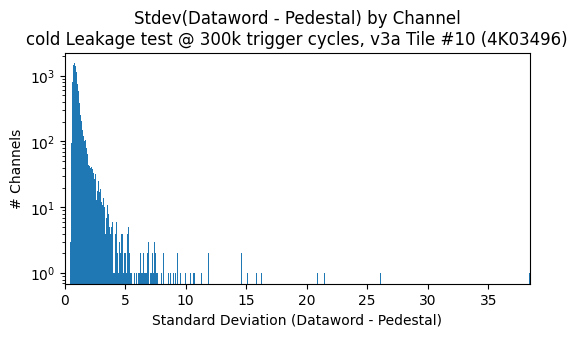

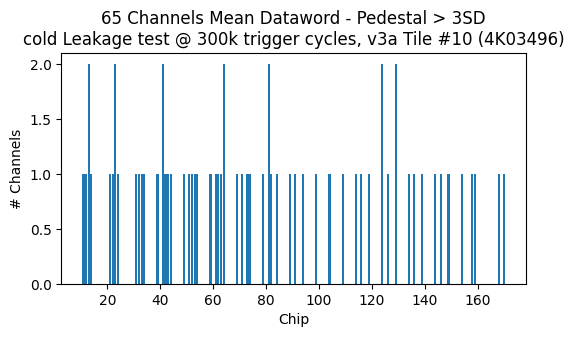

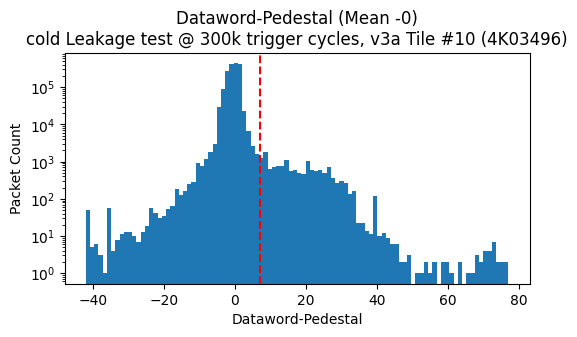

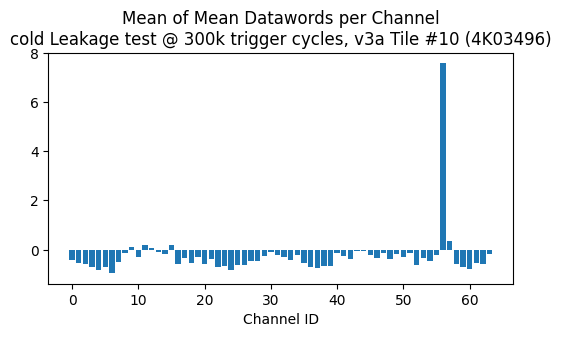

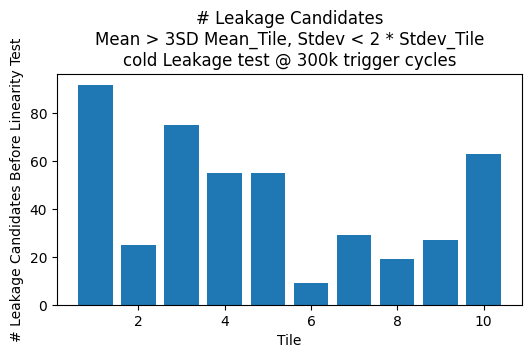

In [8]:
######
# main 
####################

print(f'Run Statistics for Data File {filename}:')

# get the channel-specific results dictionary that holds results for all tiles from all tests 
import_results_dictionary()

# get packets from pedestal run data file and check for various attributes
for tile in tiles:
    chip_serial_number = chip_serial_number_list[tile]
    
    get_data(filename, tile, ig)
    write_leakage_to_file(tile)

print(f'\n\n############ SUMMARY OF {ntiles} TILES TESTED #################')
nchans = n_chan_in_tile * ntiles

print(f'\nFor the {ntiles} tiles tested: \n\t{n_high_file} channels had mean(dataword-pedestal) > {nstdev} Stdev')
print(f'\t{leakage_count_file} (or {leakage_count_file/nchans:.03f}%) are leakage candidates (i.e. high word-pedestal AND low stdev)') 
print(f'\t{noisy_count_file} (or {noisy_count_file/nchans:.03f}%) are noisy channels (i.e. high word-pedestal BUT high stdev)')
print(f'\t{n_chan56} were from channel 56')

store_results()

print(f'\n###############################################################\n')

for i in range(64):
    mean_of_means.append(np.mean(means[i]))
    chan_list.append(i)

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(chan_list, mean_of_means)
ax.set_title(f'Mean of Mean Datawords per Channel\n{temp} Leakage test @ {file_cycles} trigger cycles, v3a Tile #{tile} ({chip_serial_number})')
ax.set_xlabel(f'Channel ID')
plt.show

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(tiles, leakage_counts)
ax.set_title(f'# Leakage Candidates\nMean > {nstdev}SD Mean_Tile, Stdev < 2 * Stdev_Tile\n{temp} Leakage test @ {file_cycles} trigger cycles')
ax.set_xlabel(f'Tile')
ax.set_ylabel(f'# Leakage Candidates Before Linearity Test')

plt.show
